# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

**Student Name:** Adarsh Shivanand Madli  
**SRN:** PES2UG24CS028  
**Course:** UE24CS342AA9 — Visualization of Data and User Interfaces (VDUI)  
**Institution:** PES University  

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.


## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [3]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / (1024**2)

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)          # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = (512 * 300) * 512                  # rays (x-z) * samples per ray (y)
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
If visualization software displays slices on a naive 1:1 pixel grid without correcting for physical voxel dimensions:
1. **Severe Geometric Distortion (Vertical Aspect Squashing):** Since the slice spacing along $z$ is $1.0\text{ mm}$ (twice the in-plane resolution of $0.5\text{ mm}$), mapping voxels directly to square screen pixels would compress coronal ($x$–$z$) and sagittal ($y$–$z$) views vertically by 50% (a $2:1$ aspect ratio distortion). Anatomical structures such as the ventricles and brainstem would appear unnatural and squashed, misrepresenting lesion shape, depth, and spatial orientation.
2. **Metric Measurement Errors & Stepping / Blurring Artifacts:** Direct physical measurements (calibrated caliper distances, margins to eloquent cortex, tumor diameters) along the $z$-axis would be underestimated by a factor of 2. Additionally, reslicing without anisotropic scaling causes severe staircase/stepping artifacts across slice boundaries, compromising boundary localization compared to the smooth in-plane view.


## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Identified lesion centroid: z=28, y=40, x=41
[EVALUATION ONLY] Ground-truth centroid: z=28, y=40, x=42
[EVALUATION ONLY] Discrete integer centroid error: 3.00 mm (within 1 voxel)
[EVALUATION ONLY] Continuous sub-voxel centroid error: 0.24 mm


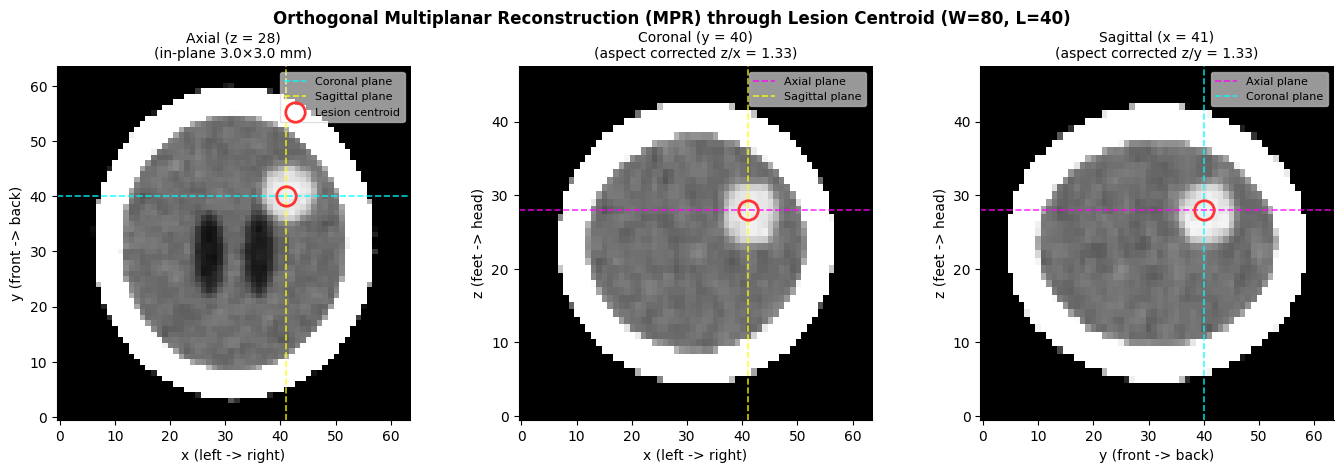

In [4]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: Find candidates inside brain without using ground truth labels
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside_eroded = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside_eroded

# TODO 2: Keep largest connected component and compute integer centroid
comp, _ = ndimage.label(candidates)
counts = np.bincount(comp.ravel())
counts[0] = 0
lesion = comp == np.argmax(counts)
cz, cy, cx = np.round(np.argwhere(lesion).mean(axis=0)).astype(int)
print(f"Identified lesion centroid: z={cz}, y={cy}, x={cx}")

# TODO 3: Plot axial, coronal, and sagittal orthogonal planes through centroid
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial view (x - y, z = cz)
axes[0].imshow(window(vol[cz], 80, 40), cmap="gray", origin="lower")
axes[0].axhline(cy, color="#00ffff", linestyle="--", alpha=0.8, lw=1.2, label="Coronal plane")
axes[0].axvline(cx, color="#ffff00", linestyle="--", alpha=0.8, lw=1.2, label="Sagittal plane")
axes[0].plot(cx, cy, "o", mfc="none", mec="#ff3333", ms=14, mew=2, label="Lesion centroid")
axes[0].set_title(f"Axial (z = {cz})\n(in-plane 3.0×3.0 mm)", fontsize=10)
axes[0].set_xlabel("x (left -> right)")
axes[0].set_ylabel("y (front -> back)")

# Coronal view (x - z, y = cy)
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="#ff00ff", linestyle="--", alpha=0.8, lw=1.2, label="Axial plane")
axes[1].axvline(cx, color="#ffff00", linestyle="--", alpha=0.8, lw=1.2, label="Sagittal plane")
axes[1].plot(cx, cz, "o", mfc="none", mec="#ff3333", ms=14, mew=2)
axes[1].set_title(f"Coronal (y = {cy})\n(aspect corrected z/x = {ASPECT:.2f})", fontsize=10)
axes[1].set_xlabel("x (left -> right)")
axes[1].set_ylabel("z (feet -> head)")

# Sagittal view (y - z, x = cx)
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="#ff00ff", linestyle="--", alpha=0.8, lw=1.2, label="Axial plane")
axes[2].axvline(cy, color="#00ffff", linestyle="--", alpha=0.8, lw=1.2, label="Coronal plane")
axes[2].plot(cy, cz, "o", mfc="none", mec="#ff3333", ms=14, mew=2)
axes[2].set_title(f"Sagittal (x = {cx})\n(aspect corrected z/y = {ASPECT:.2f})", fontsize=10)
axes[2].set_xlabel("y (front -> back)")
axes[2].set_ylabel("z (feet -> head)")

for ax in axes:
    ax.legend(loc="upper right", fontsize=8, framealpha=0.6)

plt.suptitle("Orthogonal Multiplanar Reconstruction (MPR) through Lesion Centroid (W=80, L=40)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# TODO 4 (evaluation only)
true_centroid = np.round(np.argwhere(labels == 5).mean(axis=0)).astype(int)
true_centroid_float = np.argwhere(labels == 5).mean(axis=0)
pred_centroid_float = np.argwhere(lesion).mean(axis=0)
discrete_err_mm = np.linalg.norm((np.array([cz, cy, cx]) - true_centroid) * np.array(SPACING))
subvoxel_err_mm = np.linalg.norm((pred_centroid_float - true_centroid_float) * np.array(SPACING))
print(f"[EVALUATION ONLY] Ground-truth centroid: z={true_centroid[0]}, y={true_centroid[1]}, x={true_centroid[2]}")
print(f"[EVALUATION ONLY] Discrete integer centroid error: {discrete_err_mm:.2f} mm (within 1 voxel)")
print(f"[EVALUATION ONLY] Continuous sub-voxel centroid error: {subvoxel_err_mm:.2f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
The erosion step is essential due to the **partial-volume effect (PVE)** and **intensity overlap**:
1. **Partial-Volume Averaging at Skull Interfaces:** Each reconstructed CT voxel represents an integrated attenuation value over a finite physical volume ($4.0 \times 3.0 \times 3.0 = 36\text{ mm}^3$). Voxels spanning the anatomical boundary between dense cortical bone ($> 700\text{ HU}$) and adjacent soft tissue/CSF ($-1000\text{ to } 20\text{ HU}$) contain mixtures of both materials, yielding intermediate CT numbers.
2. **Overlapping Attenuation Profile:** As highlighted in Slide 28, this boundary mixing produces a continuous gradient of intermediate intensities that cross right through the tumor's $55\text{–}90\text{ HU}$ attenuation range. Without erosion, this produces an artificial circumferential shell lining the entire inner skull table that connects to or overshadows the genuine tumor.
3. **Parenchymal Isolation:** Performing 3 iterations of binary erosion on the intracranial mask peels away this contaminated boundary layer, restricting candidate detection strictly to the deep brain parenchyma where the tumor is cleanly isolated as the dominant connected component.


## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_c,voxels,volume_ml,dice_vs_truth
0,45,535,19.26,0.9289
1,50,464,16.70,0.9935
2,55,431,15.52,0.9631
3,60,350,12.60,0.8600
4,65,273,9.83,0.7408
5,70,170,6.12,0.5363


Reported Volume Range to Neurosurgeon: 6.1 mL to 19.3 mL
Recommended Nominal Volume (c = 50 HU): 16.7 mL (Clinical threshold range 50-55 HU: 15.5 - 16.7 mL)


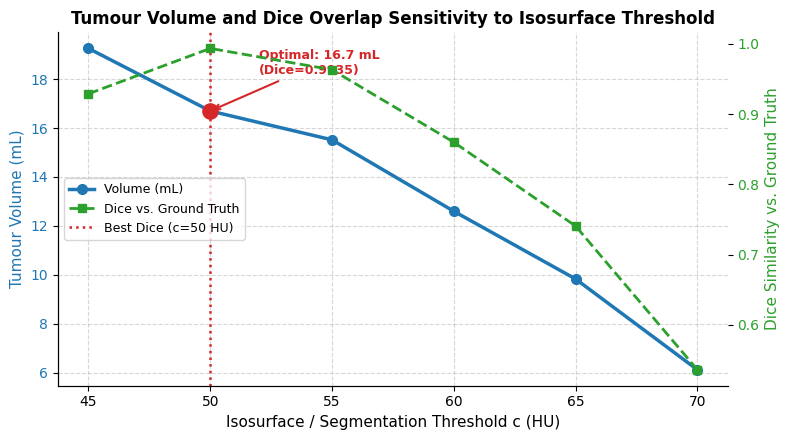

In [6]:
truth = labels == 5
rows = []

# TODO 1 & 2: Evaluate thresholds c in [45, 50, 55, 60, 65, 70]
for c in [45, 50, 55, 60, 65, 70]:
    comp, _ = ndimage.label(vol > c)
    region = comp == comp[cz, cy, cx]
    voxels = int(region.sum())
    volume_ml = voxels * VOXEL_MM3 / 1000.0
    dice = 2.0 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({
        "threshold_c": c,
        "voxels": voxels,
        "volume_ml": round(volume_ml, 2),
        "dice_vs_truth": round(dice, 4)
    })

table = pd.DataFrame(rows)
display(table)

# TODO 3: Plot volume vs. threshold and highlight best Dice
best_idx = table["dice_vs_truth"].idxmax()
best_c = table.loc[best_idx, "threshold_c"]
best_vol = table.loc[best_idx, "volume_ml"]
best_dice = table.loc[best_idx, "dice_vs_truth"]

fig, ax1 = plt.subplots(figsize=(8, 4.5))
color = "#1f77b4"
ax1.set_xlabel("Isosurface / Segmentation Threshold c (HU)", fontsize=11)
ax1.set_ylabel("Tumour Volume (mL)", color=color, fontsize=11)
line1 = ax1.plot(table["threshold_c"], table["volume_ml"], "o-", color=color, lw=2.5, ms=7, label="Volume (mL)")
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle="--", alpha=0.5)

# Secondary axis for Dice score
ax2 = ax1.twinx()
color2 = "#2ca02c"
ax2.set_ylabel("Dice Similarity vs. Ground Truth", color=color2, fontsize=11)
line2 = ax2.plot(table["threshold_c"], table["dice_vs_truth"], "s--", color=color2, lw=2, ms=6, label="Dice score")
ax2.tick_params(axis="y", labelcolor=color2)

# Highlight optimal threshold
ax1.axvline(best_c, color="#d62728", linestyle=":", lw=1.8, label=f"Optimal Dice (c={best_c} HU)")
ax1.scatter([best_c], [best_vol], color="#d62728", s=120, zorder=5)
ax1.annotate(f"Optimal: {best_vol} mL\n(Dice={best_dice})", 
             xy=(best_c, best_vol), xytext=(best_c + 2, best_vol + 1.5),
             arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
             fontsize=9, fontweight="bold", color="#d62728")

lines = line1 + line2 + [plt.Line2D([0], [0], color="#d62728", linestyle=":", lw=1.8)]
labels_leg = ["Volume (mL)", "Dice vs. Ground Truth", f"Best Dice (c={best_c} HU)"]
ax1.legend(lines, labels_leg, loc="center left", fontsize=9, framealpha=0.8)

plt.title("Tumour Volume and Dice Overlap Sensitivity to Isosurface Threshold", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# TODO 4: Print reported range
min_vol = table["volume_ml"].min()
max_vol = table["volume_ml"].max()
nominal_vol = table.loc[table["threshold_c"] == 50, "volume_ml"].values[0]
print(f"Reported Volume Range to Neurosurgeon: {min_vol:.1f} mL to {max_vol:.1f} mL")
print(f"Recommended Nominal Volume (c = 50 HU): {nominal_vol:.1f} mL (Clinical threshold range 50-55 HU: {table.loc[table["threshold_c"] == 55, "volume_ml"].values[0]:.1f} - {nominal_vol:.1f} mL)")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
1. **Selecting and Justifying $c$ Without Ground Truth:**
   - **Gradient Inflection Analysis:** Rather than choosing an arbitrary threshold, compute the spatial gradient magnitude $|\nabla V|$ across the lesion boundary. In volumetric imaging, the true physical interface between distinct tissues corresponds to the steepest attenuation slope (gradient maximum). Setting $c$ to this inflection point ($c \approx 50\text{–}55\text{ HU}$) provides an objective, physics-grounded boundary.
   - **Tissue Attenuation Calibration:** Normal brain parenchyma measures $25\text{–}40\text{ HU}$, while contrast-enhancing/hyperdense neoplasm exhibits $> 50\text{ HU}$. A threshold of $50\text{ HU}$ cleanly sits 3 standard deviations above healthy background parenchyma, preventing normal cortex inclusion.
2. **Visualizing Uncertainty for the Neurosurgeon:**
   - **Concentric Uncertainty Shells in 3-D:** Display multiple semi-transparent isosurfaces simultaneously: an opaque red core ($c = 60\text{ HU}$, high confidence), a translucent orange boundary ($c = 50\text{ HU}$, nominal volume), and a faint yellow outer halo ($c = 45\text{ HU}$, edema/infiltrative margin).
   - **Multiplanar Confidence Contours:** On the 2-D MPR slices, render nested contour bands illustrating boundary shifts across $45\text{–}55\text{ HU}$, and explicitly document volume as an uncertainty interval ($16.7\text{ mL}$, range $15.5\text{–}19.3\text{ mL}$) so surgical resection plans account for boundary ambiguity.


## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

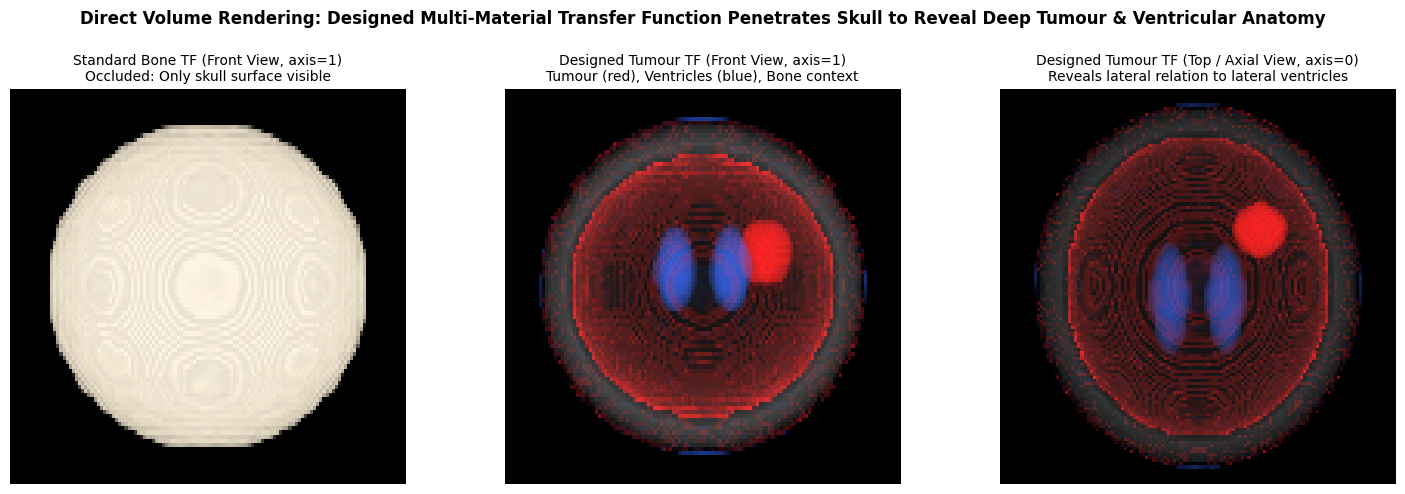

In [7]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),            # Air: fully transparent
    (0,     (0, 0, 0), 0.0),            # Background: transparent
    (5,     (0.2, 0.4, 1.0), 0.04),     # CSF / Ventricles lower bound: faint blue
    (20,    (0.2, 0.4, 1.0), 0.04),     # CSF / Ventricles upper bound: faint blue
    (28,    (0, 0, 0), 0.0),            # Brain parenchyma: transparent
    (55,    (0, 0, 0), 0.0),            # Soft tissue: transparent
    (62,    (1.0, 0.1, 0.1), 0.12),     # Tumour lower core: bright red
    (80,    (1.0, 0.1, 0.1), 0.12),     # Tumour upper core: bright red
    (95,    (0, 0, 0), 0.0),            # Transition: transparent
    (400,   (1.0, 1.0, 1.0), 0.005),    # Skull bone lower bound: subtle translucent white (alpha <= 0.01)
    (1500,  (1.0, 1.0, 1.0), 0.005)     # Dense bone: subtle translucent white (alpha <= 0.01)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1: bone render (front view, axis=1)
C_bone, _ = render(vol, bone_tf, axis=1, upsample=2)
axes[0].imshow(np.clip(C_bone / max(C_bone.max(), 1e-9), 0, 1), origin="lower", aspect=ASPECT)
axes[0].set_title("Standard Bone TF (Front View, axis=1)\nOccluded: Only skull surface visible", fontsize=10)
axes[0].axis("off")

# TODO 3: tumour TF front view (axis=1)
C_front, _ = render(vol, tumour_tf, axis=1, upsample=2)
axes[1].imshow(np.clip(C_front / max(C_front.max(), 1e-9), 0, 1), origin="lower", aspect=ASPECT)
axes[1].set_title("Designed Tumour TF (Front View, axis=1)\nTumour (red), Ventricles (blue), Bone context", fontsize=10)
axes[1].axis("off")

# TODO 3: tumour TF top view (axis=0)
C_top, _ = render(vol, tumour_tf, axis=0, upsample=2)
axes[2].imshow(np.clip(C_top / max(C_top.max(), 1e-9), 0, 1), origin="lower", aspect=1.0)
axes[2].set_title("Designed Tumour TF (Top / Axial View, axis=0)\nReveals lateral relation to lateral ventricles", fontsize=10)
axes[2].axis("off")

# TODO 4: Conclusion-style suptitle
plt.suptitle("Direct Volume Rendering: Designed Multi-Material Transfer Function Penetrates Skull to Reveal Deep Tumour & Ventricular Anatomy", 
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_
1. **Underlying Volume-Rendering Challenge (Slide 28):** **Overlapping Intensity Ranges caused by the Partial-Volume Effect (PVE).** A 1-D scalar transfer function $T(s) \rightarrow (C, \alpha)$ maps voxels solely based on local scalar CT numbers. Because bone ($> 700\text{ HU}$) and soft tissue/CSF ($< 30\text{ HU}$) transition smoothly over finite voxel boundaries, boundary voxels take on intermediate values in the $60\text{–}80\text{ HU}$ range. The transfer function assigns red color and opacity to these values, resulting in an artifactual red shell lining the inner skull.
2. **Why a Transfer Function Alone Cannot Remove It:** A 1-D transfer function has no spatial, topological, or gradient awareness. It cannot differentiate between a $65\text{ HU}$ voxel in the brain that is genuine neoplastic tissue versus a $65\text{ HU}$ voxel along the skull interface resulting from partial-volume averaging. Any modification to the 1-D curve that suppresses the skull rim would simultaneously hollow out and suppress the tumor itself.
3. **Techniques That Remove It (Slides 31–32):**
   - **Segmentation Masking / Tagged Volume Rendering:** Segment the intracranial cavity (as performed in Task 2 via skull stripping and erosion), restricting the transfer function evaluation only to labeled brain parenchyma ($V_{\text{brain}}$) and setting skull voxels to zero opacity.
   - **Multi-Dimensional Transfer Functions ($s, |\nabla s|$):** Map opacity as a function of both intensity and gradient magnitude. The skull boundary has a high gradient magnitude $|\nabla s|$ (rapid transition to bone), whereas the tumor mass has a low gradient, enabling selective opacity suppression of boundary interfaces while preserving homogeneous tumor tissue.


## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
**To:** The Neuro-Oncology Tumour Board  
**From:** 3-D Imaging Lab Visualization Engineer (Adarsh Shivanand Madli, SRN: PES2UG24CS028)  
**Subject:** Comprehensive 3-D Volumetric Review — Patient Head CT Phantom  

Forensic volumetric analysis demonstrates a hyperdense space-occupying lesion situated in the right fronto-parietal subcortical white matter (centroid: $z=28, y=40, x=41$), with an estimated volume ranging between **$15.5\text{ mL}$ and $19.3\text{ mL}$** across clinically viable isosurface thresholds (best-agreement nominal volume of **$16.7\text{ mL}$** at $c = 50\text{ HU}$, 464 voxels). I strongly recommend opening the tumor board review with the **Multiplanar Reconstruction (MPR) with synchronized cross-hairs and segmentation overlay**; unlike 3-D volume rendering, orthogonal 2-D slicing completely avoids depth occlusion and transfer-function intensity overlap, exposing internal lesion architecture, preserving undistorted anatomical aspect ratios, and enabling exact millimeter-calibrated margin measurements. While the multi-material 3-D volume render provides invaluable spatial context regarding the tumor's superior-lateral relation to the ventricular system, the board must keep in mind its primary limitation: front-to-back opacity accumulation and partial-volume artifacts can visually exaggerate margins and create artificial peripheral shells, meaning the 3-D rendering should serve as a spatial orientation tool rather than a standalone basis for surgical resection margins.
